# Oil and Gas Production Data Analysis

## Project Overview

This project explores oil and gas production data from the U.S. Bureau of Safety and Environmental Enforcement (BSEE) for the year 2024.

The aim is to examine production patterns, identify trends and variations, investigate relationships between production variables, and generate insights from the data.

## Project Objectives

- Explore the structure and characteristics of the dataset.
- Identify missing values, duplicates, and possible data-quality issues.
- Examine monthly oil, gas, water, and injection production trends.
- Compare production volumes across wells and operators.
- Investigate relationships between selected production variables.
- Present findings through appropriate visualisations.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

columns = [
    "lease_number",
    "completion_name",
    "production_date",
    "days_on_prod",
    "product_code",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "api_well_number",
    "well_status_code",
    "area_block",
    "operator_number",
    "operator_name",
    "field_name_code",
    "injection_volume",
    "production_interval_code",
    "first_production_date",
    "unit_agreement_number",
    "unit_allocation_suffix"
]

df = pd.read_csv(
    r"C:\Users\USER\CodeAlpha_Oil_Gas_Production_Analysis\data\ogora2024delimit.txt",
    sep=",",
    header=None,
    names=columns,
    dtype=str
)

numeric_columns = [
    "days_on_prod",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "injection_volume"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.shape)

(62836, 19)


In [15]:
print("Dataset shape:", df.shape)

Dataset shape: (62836, 19)


In [16]:
df.head()

,lease_number,completion_name,production_date,days_on_prod,product_code,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,api_well_number,well_status_code,area_block,operator_number,operator_name,field_name_code,injection_volume,production_interval_code,first_production_date,unit_agreement_number,unit_allocation_suffix
0,00016,E002,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q04,19720331,NaN,NaN
1,00016,E002D,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q01,19610228,NaN,NaN
2,00016,E002Q,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q64,NaN,NaN,NaN
3,00016,E002T,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q65,NaN,NaN,NaN
4,00016,E016,202401,0,G,0,0,0,177194064700,13,WD 31,03151,COX OPERATING LLC,WD030,0,S03,20000605,NaN,NaN


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62836 entries, 0 to 62835
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   lease_number              62825 non-null  object
 1   completion_name           62820 non-null  object
 2   production_date           62836 non-null  object
 3   days_on_prod              62836 non-null  int64 
 4   product_code              62836 non-null  object
 5   monthly_oil_volume        62836 non-null  int64 
 6   monthly_gas_volume        62836 non-null  int64 
 7   monthly_water_volume      62836 non-null  int64 
 8   api_well_number           62836 non-null  object
 9   well_status_code          62836 non-null  object
 10  area_block                62836 non-null  object
 11  operator_number           62836 non-null  object
 12  operator_name             62836 non-null  object
 13  field_name_code           62836 non-null  object
 14  injection_volume      

In [18]:
df.describe()

,days_on_prod,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,injection_volume
count,62836.000000,62836.000000,6.283600e+04,62836.000000,6.283600e+04
mean,8.598813,10443.326119,1.092864e+04,6302.652444,3.330264e+03
std,12.908514,45734.124936,5.647630e+04,25929.361792,4.313239e+04
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
50%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
75%,24.000000,611.000000,6.942500e+02,494.250000,0.000000e+00
max,31.000000,711866.000000,1.551124e+06,572660.000000,1.664516e+06


In [19]:
numeric_columns = [
    "days_on_prod",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "injection_volume"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Numeric columns converted successfully!")

Numeric columns converted successfully!


In [20]:
df.dtypes

lease_number                object
completion_name             object
production_date             object
days_on_prod                 int64
product_code                object
monthly_oil_volume           int64
monthly_gas_volume           int64
monthly_water_volume         int64
api_well_number             object
well_status_code            object
area_block                  object
operator_number             object
operator_name               object
field_name_code             object
injection_volume             int64
production_interval_code    object
first_production_date       object
unit_agreement_number       object
unit_allocation_suffix      object
dtype: object

In [21]:
df.isnull().sum()

lease_number                   11
completion_name                16
production_date                 0
days_on_prod                    0
product_code                    0
monthly_oil_volume              0
monthly_gas_volume              0
monthly_water_volume            0
api_well_number                 0
well_status_code                0
area_block                      0
operator_number                 0
operator_name                   0
field_name_code                 0
injection_volume                0
production_interval_code        0
first_production_date       21873
unit_agreement_number       46420
unit_allocation_suffix      46420
dtype: int64

In [22]:
df.duplicated().sum()

0

In [23]:
df["production_date"].value_counts().sort_index()

production_date
202401    6133
202402    5170
202403    5179
202404    5173
202405    5177
202406    5169
202407    5168
202408    5165
202409    5160
202410    5160
202411    5095
202412    5087
Name: count, dtype: int64

In [24]:
df[numeric_columns].describe()

,days_on_prod,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,injection_volume
count,62836.000000,62836.000000,6.283600e+04,62836.000000,6.283600e+04
mean,8.598813,10443.326119,1.092864e+04,6302.652444,3.330264e+03
std,12.908514,45734.124936,5.647630e+04,25929.361792,4.313239e+04
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
50%,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
75%,24.000000,611.000000,6.942500e+02,494.250000,0.000000e+00
max,31.000000,711866.000000,1.551124e+06,572660.000000,1.664516e+06


### Descriptive Statistics – Key Observations

The descriptive statistics reveal considerable variation in the production data. All five numerical variables have a median value of zero, indicating that at least half of the records contain zero values for each variable.

The mean values are considerably higher than the medians, suggesting that production volumes are unevenly distributed, with some records having substantially higher values than others.

Production days range from 0 to 31, which is consistent with monthly reporting.

These observations suggest the need to investigate zero production values and understand the distribution of the recorded production volumes before proceeding with further analysis.

In [25]:
(df[numeric_columns] == 0).sum()

days_on_prod            41453
monthly_oil_volume      43094
monthly_gas_volume      42776
monthly_water_volume    44159
injection_volume        61963
dtype: int64

### Analysis of Zero Values

The analysis shows that zero values are common across the numerical production variables. Approximately 65.97% of records have zero production days, while 68.58%, 68.08%, and 70.28% have zero oil, gas, and water volumes, respectively.

Injection volume has the highest proportion of zero values at approximately 98.61%.

These zero values are not automatically considered data errors, as they may represent periods of no recorded production or injection activity. Therefore, they are retained for further analysis.

In [26]:
(df[numeric_columns] < 0).sum()

days_on_prod            0
monthly_oil_volume      0
monthly_gas_volume      0
monthly_water_volume    0
injection_volume        0
dtype: int64

### Check for Negative Values

No negative values were found in the five numerical variables examined. All recorded production volumes, injection volumes, and production days are zero or positive.

In [27]:
(df["days_on_prod"] > 31).sum()

0

In [28]:
(df["days_on_prod"].eq(0) & df["monthly_oil_volume"].gt(0)).sum()

0

### Production Days and Oil Volume Consistency Check

No records were found with positive oil production and zero production days. This indicates consistency between these two variables within the dataset.

In [29]:
(df["days_on_prod"].gt(0) & df["monthly_oil_volume"].eq(0)).sum()

1641

### Records with Production Days but Zero Oil Volume

A total of 1,641 records were identified with positive production days but zero recorded oil volume.

These records may represent production activity involving gas or water without recorded oil production. Therefore, they are not automatically classified as errors. Further interpretation would require additional information about the product classifications and reporting definitions.

In [30]:
monthly_production = df.groupby("production_date").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum")
)

monthly_production

,total_oil,total_gas
production_date,,
202401,54389450,61175454
202402,52667184,56305118
202403,55955176,55946856
202404,55791282,58296677
202405,55902618,55369683
202406,54632345,56775058
202407,56845228,60181436
202408,57156809,60724077
202409,48320873,49616309


### Monthly Oil and Gas Production – Initial Observations

The monthly production totals show fluctuations in both oil and gas volumes throughout 2024.

December recorded the highest monthly oil production, while August recorded the highest gas production. September recorded the lowest totals for both variables, followed by a noticeable increase in October.

These variations highlight changes in recorded production volumes across the reporting period. However, the data alone does not establish the operational causes of these fluctuations.

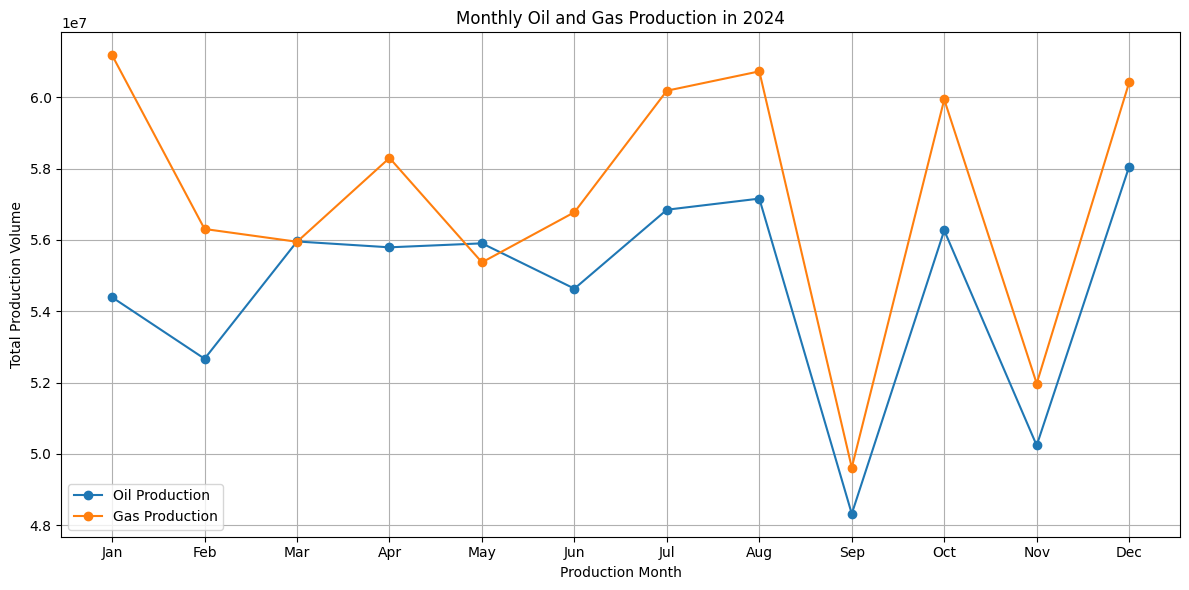

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_production.index, monthly_production["total_oil"],
         marker="o", label="Oil Production")

plt.plot(monthly_production.index, monthly_production["total_gas"],
         marker="o", label="Gas Production")

plt.title("Monthly Oil and Gas Production in 2024")
plt.xlabel("Production Month")
plt.ylabel("Total Production Volume")
plt.legend()
plt.grid(True)

plt.xticks(
    range(len(monthly_production.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

In [32]:
monthly_water_injection = df.groupby("production_date").agg(
    total_water=("monthly_water_volume", "sum"),
    total_injection=("injection_volume", "sum")
)

monthly_water_injection

,total_water,total_injection
production_date,,
202401,33721753,16478830
202402,30187516,15662977
202403,33308166,16299667
202404,32241622,15910242
202405,34140565,18043860
202406,32846127,16327191
202407,34309947,19445160
202408,35490860,20075642
202409,28129357,15014683


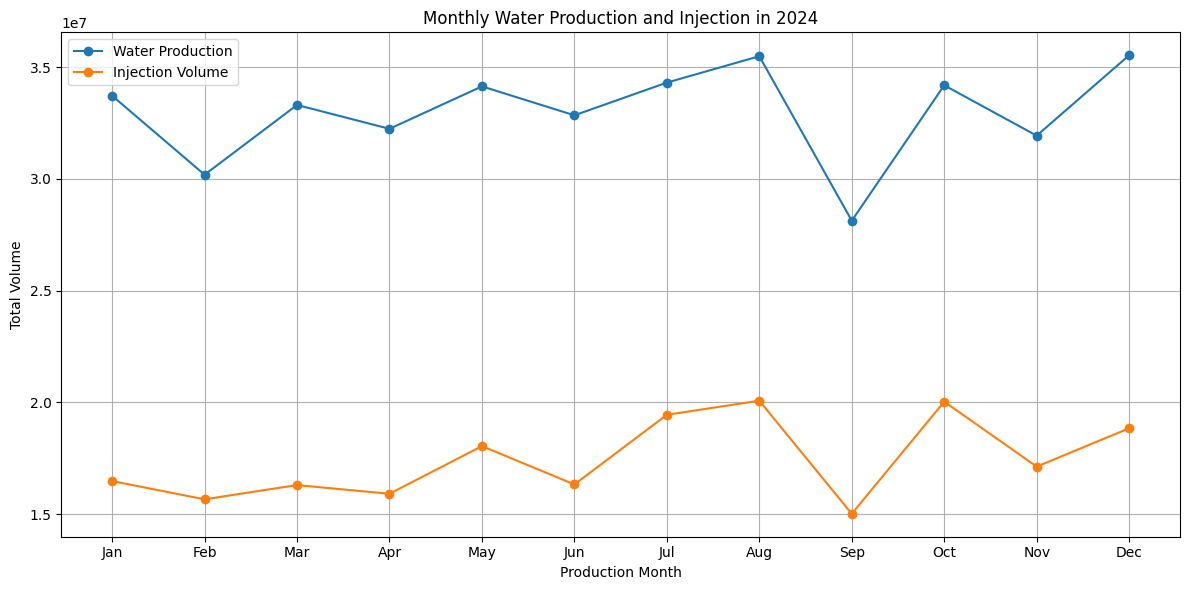

In [33]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_water_injection.index,
         monthly_water_injection["total_water"],
         marker="o", label="Water Production")

plt.plot(monthly_water_injection.index,
         monthly_water_injection["total_injection"],
         marker="o", label="Injection Volume")

plt.title("Monthly Water Production and Injection in 2024")
plt.xlabel("Production Month")
plt.ylabel("Total Volume")
plt.legend()
plt.grid(True)

plt.xticks(
    range(len(monthly_water_injection.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

In [34]:
monthly_days = df.groupby("production_date").agg(
    average_production_days=("days_on_prod", "mean")
)

monthly_days

,average_production_days
production_date,
202401,7.898908
202402,8.464797
202403,8.533694
202404,8.527354
202405,9.101603
202406,8.949313
202407,9.034443
202408,9.046854
202409,7.178876


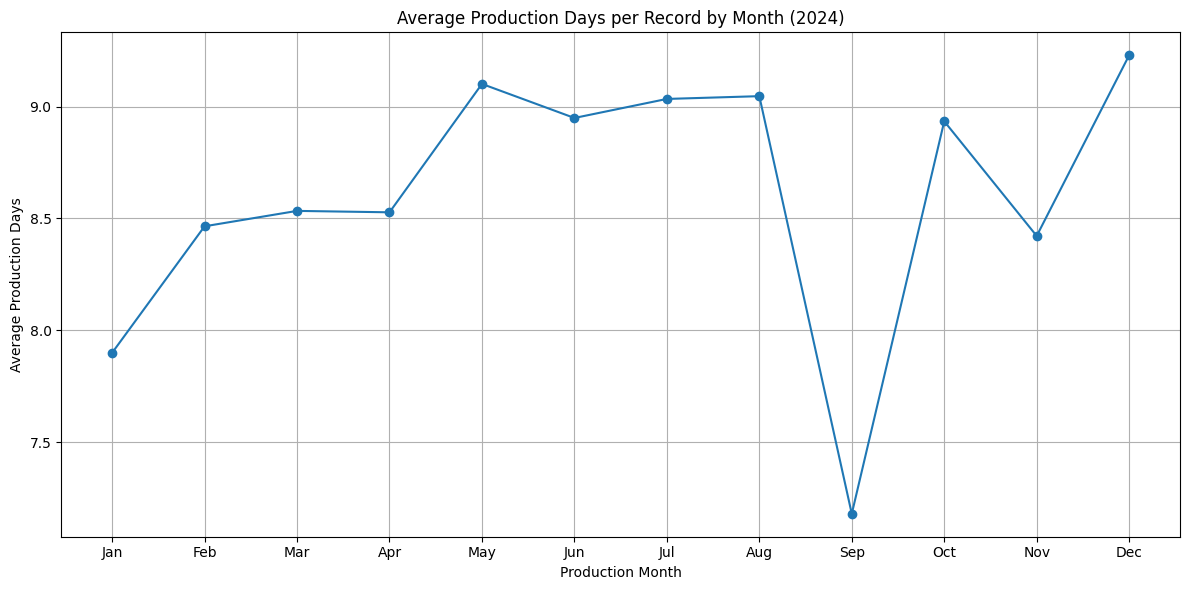

In [35]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_days.index,
    monthly_days["average_production_days"],
    marker="o"
)

plt.title("Average Production Days per Record by Month (2024)")
plt.xlabel("Production Month")
plt.ylabel("Average Production Days")
plt.xticks(
    range(len(monthly_days.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
monthly_wor = (
    monthly_water_injection["total_water"] /
    monthly_production["total_oil"]
)

monthly_wor

production_date
202401    0.620005
202402    0.573175
202403    0.595265
202404    0.577897
202405    0.610715
202406    0.601221
202407    0.603568
202408    0.620938
202409    0.582137
202410    0.607652
202411    0.635677
202412    0.612078
dtype: float64

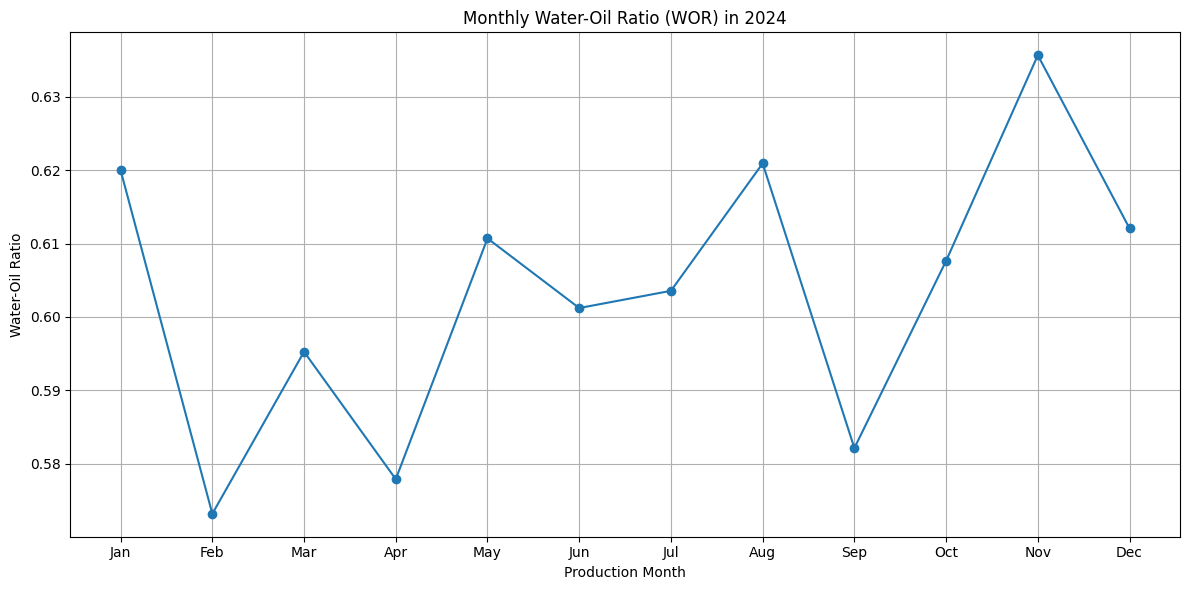

In [37]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_wor.index,
    monthly_wor.values,
    marker="o"
)

plt.title("Monthly Water-Oil Ratio (WOR) in 2024")
plt.xlabel("Production Month")
plt.ylabel("Water-Oil Ratio")
plt.xticks(
    range(len(monthly_wor.index)),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
well_production = df.groupby("api_well_number").agg(
    total_oil=("monthly_oil_volume", "sum")
)

well_production.head()

,total_oil
api_well_number,
012032016500,0
012032027100,0
012032029300,880
012032030900,0
177000000600,0


In [39]:
top_10_oil_wells = well_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

top_10_oil_wells

,total_oil
api_well_number,
608174144500,8166097
608174101101,5882419
608054005400,5644063
608174133000,5414667
608114070600,5350210
608124006001,5217804
608174132800,4957222
608174133900,4925348
608174119802,4875798


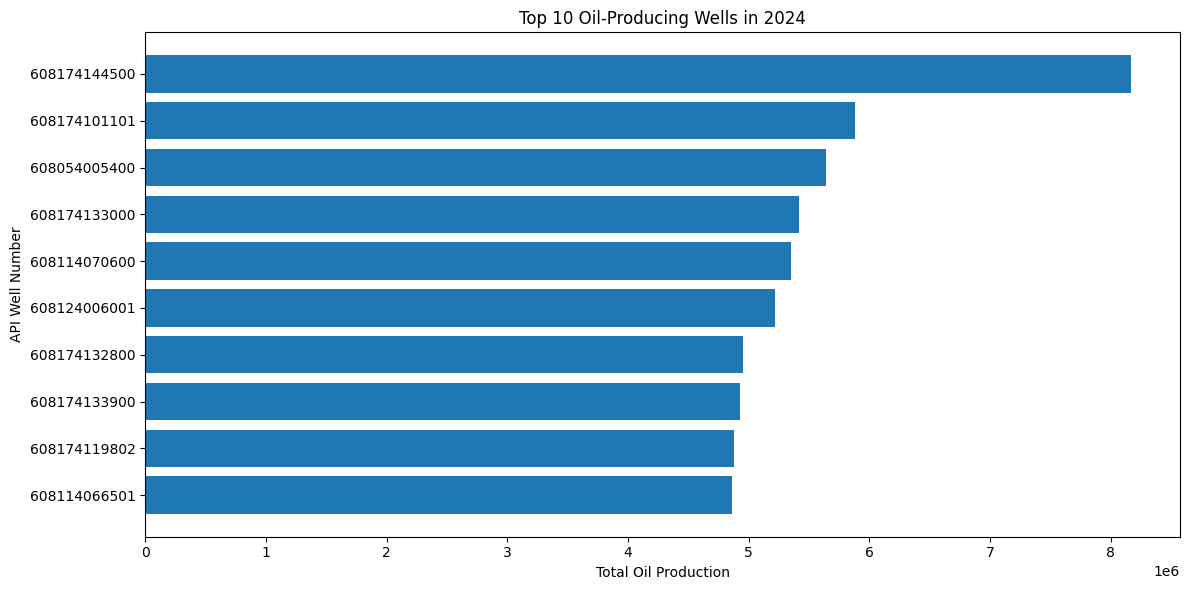

In [40]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_oil_wells.index.astype(str),
    top_10_oil_wells["total_oil"]
)

plt.title("Top 10 Oil-Producing Wells in 2024")
plt.xlabel("Total Oil Production")
plt.ylabel("API Well Number")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
well_gas = df.groupby("api_well_number").agg(
    total_gas=("monthly_gas_volume", "sum")
)

well_gas.head()

,total_gas
api_well_number,
012032016500,1141
012032027100,0
012032029300,1892672
012032030900,0
177000000600,81643


In [42]:
top_10_gas_wells = well_gas.sort_values(
    by="total_gas",
    ascending=False
).head(10)

top_10_gas_wells

,total_gas
api_well_number,
608164046801,16414218
608114072600,16334195
608114066501,13666285
608174129300,9152656
608074032700,8935031
608074008201,8483471
608114077500,7624800
608164046700,7139759
177164035900,6500042


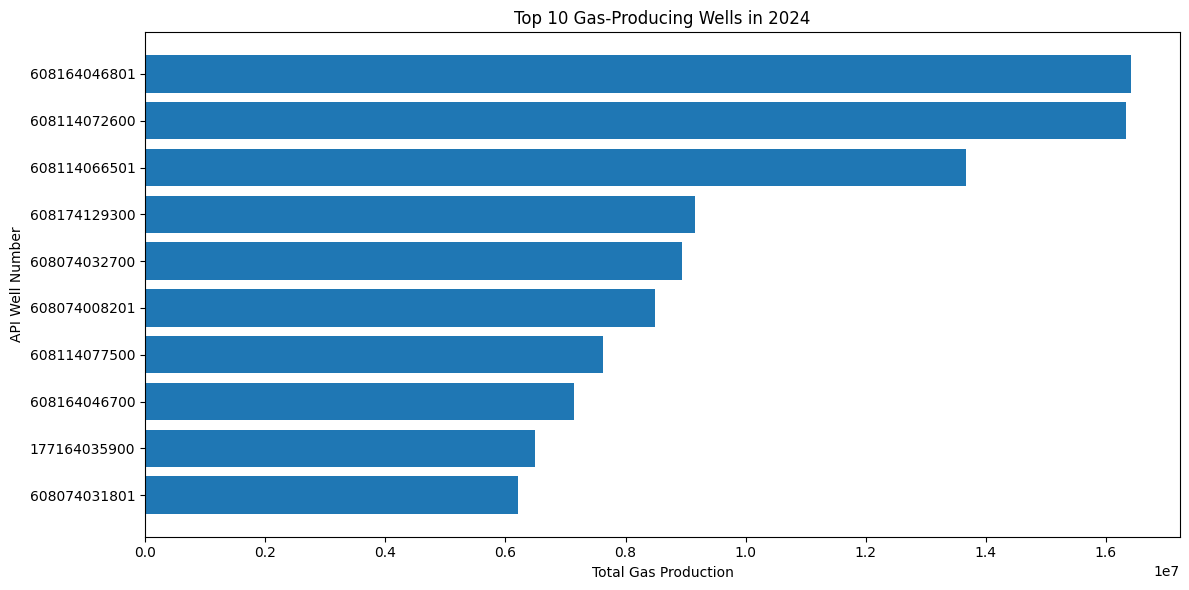

In [43]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_gas_wells.index.astype(str),
    top_10_gas_wells["total_gas"]
)

plt.title("Top 10 Gas-Producing Wells in 2024")
plt.xlabel("Total Gas Production")
plt.ylabel("API Well Number")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [44]:
well_water = df.groupby("api_well_number").agg(
    total_water=("monthly_water_volume", "sum")
)

top_10_water_wells = well_water.sort_values(
    by="total_water",
    ascending=False
).head(10)

top_10_water_wells

,total_water
api_well_number,
608174104800,5165600
608174099800,4190993
608074009002,4162246
608174143800,3933799
608174122900,3901855
608124006200,3859396
608174108600,3669514
608174132900,3499808
608174109103,3426263


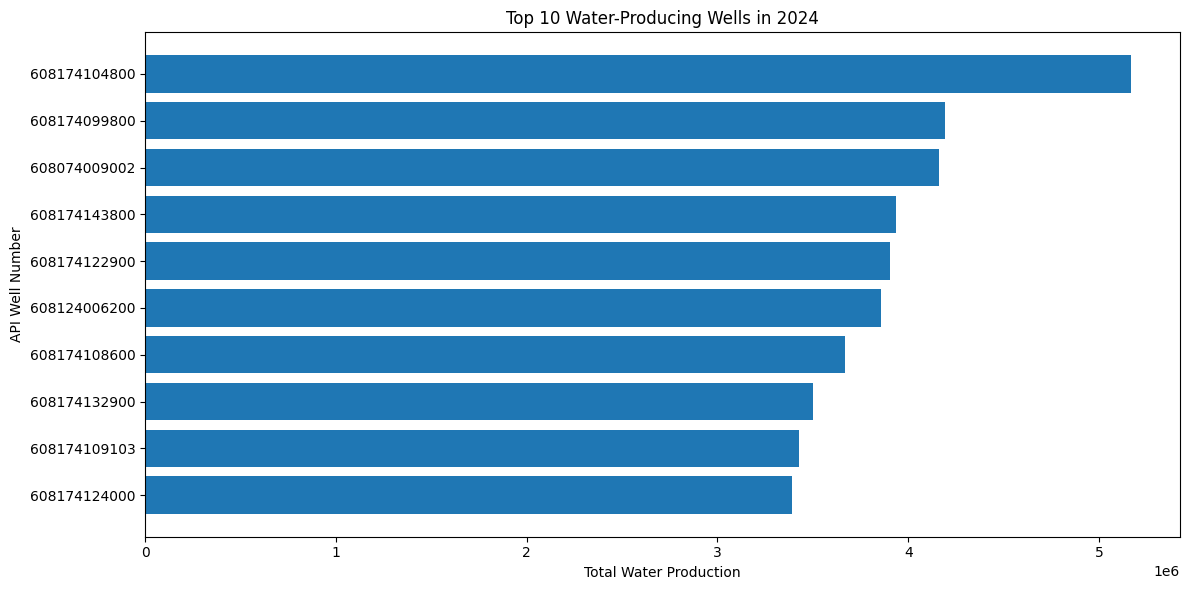

In [45]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_water_wells.index.astype(str),
    top_10_water_wells["total_water"]
)

plt.title("Top 10 Water-Producing Wells in 2024")
plt.xlabel("Total Water Production")
plt.ylabel("API Well Number")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [46]:
operator_production = df.groupby("operator_name").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum")
)

operator_production.head()

,total_oil,total_gas,total_water
operator_name,,,
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
ANKOR ENERGY LLC,0,0,0
ARENA OFFSHORE LP,8454987,22538514,56596510
ARRAY PETROLEUM LLC,991398,3040261,5419676
BEACON GROWTHCO OPERATING COMPANY LLC,5590608,7763428,1154202


In [47]:
top_10_oil_operators = operator_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

top_10_oil_operators

,total_oil,total_gas,total_water
operator_name,,,
SHELL OFFSHORE INC.,171703409,167434308,54396347
BP EXPLORATION & PRODUCTION INC,143525193,87506938,65339272
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
CHEVRON USA INC,55483282,37269893,18854495
MURPHY EXPLORATION & PRODUCTION COMPANY - USA,38903285,56059087,9144870
LLOG EXPLORATION OFFSHORE LLC,27347442,33756353,8154212
UNION OIL COMPANY OF CALIFORNIA,22217880,5304255,1339743
HESS CORPORATION,16941848,28764308,9569370
TALOS QN EXPLORATION LLC,15356770,29570177,7711810


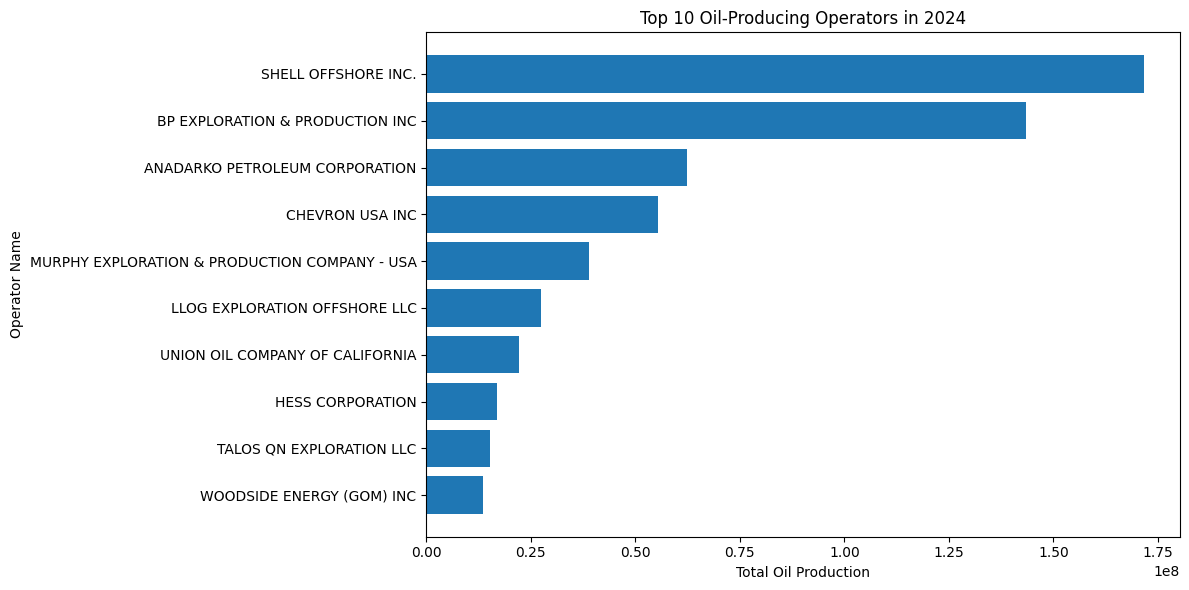

In [48]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_oil_operators.index,
    top_10_oil_operators["total_oil"]
)

plt.title("Top 10 Oil-Producing Operators in 2024")
plt.xlabel("Total Oil Production")
plt.ylabel("Operator Name")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [49]:
top_10_gas_operators = operator_production.sort_values(
    by="total_gas",
    ascending=False
).head(10)

top_10_gas_operators

,total_oil,total_gas,total_water
operator_name,,,
SHELL OFFSHORE INC.,171703409,167434308,54396347
BP EXPLORATION & PRODUCTION INC,143525193,87506938,65339272
MURPHY EXPLORATION & PRODUCTION COMPANY - USA,38903285,56059087,9144870
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
CHEVRON USA INC,55483282,37269893,18854495
LLOG EXPLORATION OFFSHORE LLC,27347442,33756353,8154212
TALOS QN EXPLORATION LLC,15356770,29570177,7711810
HESS CORPORATION,16941848,28764308,9569370
TALOS PETROLEUM LLC,7414133,24271108,8921988


### Top 10 Gas-Producing Operators

This section identifies the ten operators with the highest recorded gas production in 2024. A horizontal bar chart is used to compare their total gas production and highlight the leading operators.

In [50]:
top_10_gas_operators = operator_production.sort_values(
    by="total_gas",
).head(10)

top_10_gas_operators


,total_oil,total_gas,total_water
operator_name,,,
EC OFFSHORE PROPERTIES INC,0,0,0
ANKOR ENERGY LLC,0,0,0
KNOC EAGLE FORD CORPORATION,0,0,0
HELIS OIL & GAS COMPANY LLC,87,0,0
DANOS LLC,0,0,0
WHITNEY OIL & GAS LLC,248,56,5124
EPL OIL & GAS LLC,471,287,7218
GULF OFFSHORE LLC,0,1254,0
MONFORTE EXPLORATION L.L.C.,11002,13571,18634


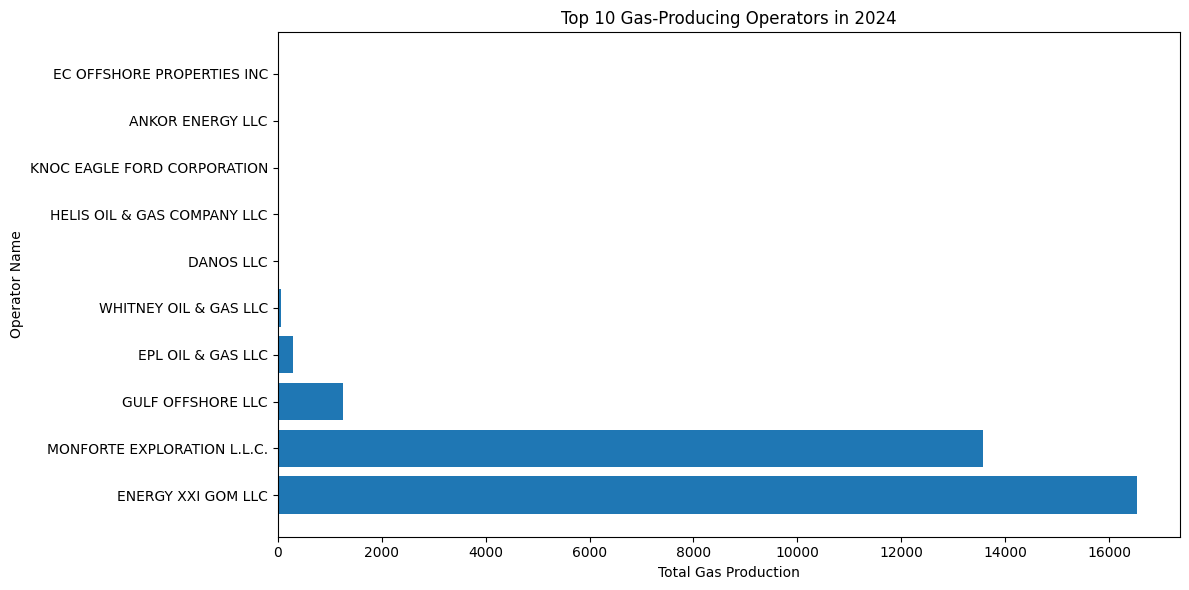

In [51]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_gas_operators.index,
    top_10_gas_operators["total_gas"]
)

plt.title("Top 10 Gas-Producing Operators in 2024")
plt.xlabel("Total Gas Production")
plt.ylabel("Operator Name")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Top 10 Water-Producing Operators

This section examines water production across different operators. Identifying operators with the highest recorded water production can help provide an overview of water production patterns within the dataset.

In [52]:
top_10_water_operators = operator_production.sort_values(
    by="total_water",
    ascending=False
).head(10)

top_10_water_operators

,total_oil,total_gas,total_water
operator_name,,,
BP EXPLORATION & PRODUCTION INC,143525193,87506938,65339272
ARENA OFFSHORE LP,8454987,22538514,56596510
SHELL OFFSHORE INC.,171703409,167434308,54396347
CANTIUM LLC,5680745,5620788,22113031
ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
CHEVRON USA INC,55483282,37269893,18854495
GOM SHELF LLC,3259467,9876215,17969945
W & T OFFSHORE INC,4582795,23866098,14833669
HESS CORPORATION,16941848,28764308,9569370


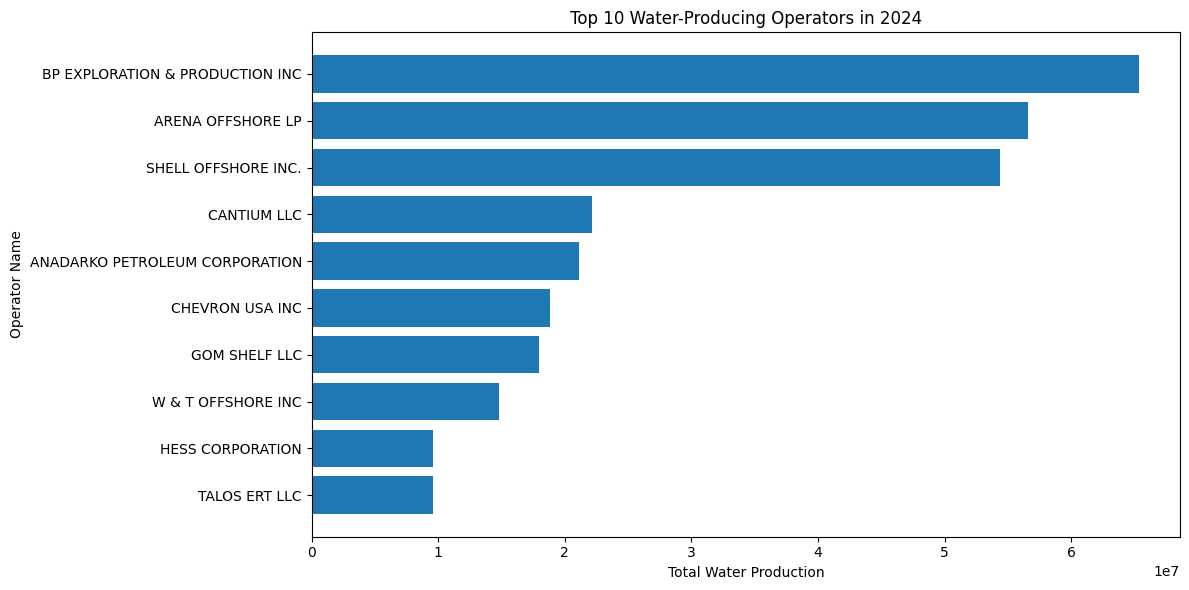

In [53]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_water_operators.index,
    top_10_water_operators["total_water"]
)

plt.title("Top 10 Water-Producing Operators in 2024")
plt.xlabel("Total Water Production")
plt.ylabel("Operator Name")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Relationship Between Oil and Water Production

This section examines the relationship between oil and water production across individual wells. Aggregating production by API well number allows us to compare the total oil and water volumes recorded for each well.

In [54]:
well_production = df.groupby("api_well_number").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum")
)

well_production.head()

,total_oil,total_gas,total_water
api_well_number,,,
012032016500,0,1141,2
012032027100,0,0,0
012032029300,880,1892672,33725
012032030900,0,0,0
177000000600,0,81643,1698


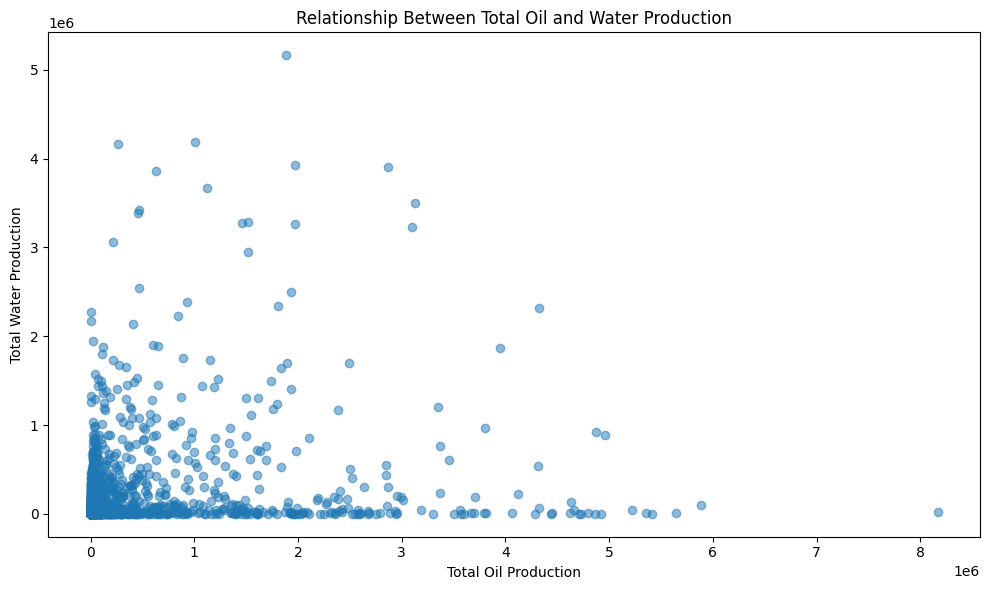

In [55]:
plt.figure(figsize=(10, 6))

plt.scatter(
    well_production["total_oil"],
    well_production["total_water"],
    alpha=0.5
)

plt.title("Relationship Between Total Oil and Water Production")
plt.xlabel("Total Oil Production")
plt.ylabel("Total Water Production")

plt.tight_layout()
plt.show()

In [56]:
oil_water_correlation = well_production[
    ["total_oil", "total_water"]
].corr()

oil_water_correlation

,total_oil,total_water
total_oil,1.000000,0.282986
total_water,0.282986,1.000000


In [57]:
oil_water_corr_value = oil_water_correlation.loc[
    "total_oil", "total_water"
]

print("Oil-Water Correlation:", round(oil_water_corr_value, 4))

Oil-Water Correlation: 0.283


### Interpretation of Oil-Water Correlation

The Pearson correlation coefficient between total oil and total water production was approximately 0.2830, indicating a weak positive linear relationship across the wells analysed.

This suggests that wells with higher oil production may also record higher water production, although the relationship is relatively weak. Therefore, oil production alone does not adequately explain variations in water production.

Further investigation using well-specific production histories and water-oil ratios would provide additional insight into individual well performance.

In [58]:
oil_gas_correlation = well_production[
    ["total_oil", "total_gas"]
].corr()

oil_gas_correlation

,total_oil,total_gas
total_oil,1.000000,0.646856
total_gas,0.646856,1.000000


In [59]:
oil_gas_corr_value = oil_gas_correlation.loc[
    "total_oil", "total_gas"
]

print("Oil-Gas Correlation:", round(oil_gas_corr_value, 4))

Oil-Gas Correlation: 0.6469


### Interpretation of Oil-Gas Correlation

The Pearson correlation coefficient between total oil and total gas production was approximately 0.6469, indicating a moderate positive linear relationship across the wells analysed.

This suggests that wells with higher oil production generally tend to record higher gas production. The relationship is stronger than the observed relationship between oil and water production.

However, correlation does not establish causation, and individual well characteristics and production conditions may influence these patterns.

In [60]:
correlation_comparison = pd.DataFrame({
    "Production Relationship": [
        "Oil and Water",
        "Oil and Gas"
    ],
    "Correlation Coefficient": [
        oil_water_corr_value,
        oil_gas_corr_value
    ]
})

correlation_comparison

,Production Relationship,Correlation Coefficient
0,Oil and Water,0.282986
1,Oil and Gas,0.646856


### Comparison of Production Relationships

The correlation analysis shows that oil and gas production have a moderate positive relationship (0.6469), while oil and water production have a weak positive relationship (0.2830).

This indicates that oil production varies more closely with gas production than with water production across the wells analysed.

These findings provide insight into the production patterns in the dataset, although correlation alone cannot establish causal relationships.

In [61]:
well_production["WOR"] = np.where(
    well_production["total_oil"] > 0,
    well_production["total_water"] / well_production["total_oil"],
    np.nan
)

well_production[["total_oil", "total_water", "WOR"]].head(10)

,total_oil,total_water,WOR
api_well_number,,,
012032016500,0,2,NaN
012032027100,0,0,NaN
012032029300,880,33725,38.323864
012032030900,0,0,NaN
177000000600,0,1698,NaN
177000026100,0,0,NaN
177000031300,0,0,NaN
177002006800,0,0,NaN
177002007100,0,0,NaN


In [62]:
top_10_wor_wells = well_production[
    well_production["WOR"].notna()
].sort_values(
    by="WOR",
    ascending=False
).head(10)

top_10_wor_wells[
    ["total_oil", "total_water", "WOR"]
]

,total_oil,total_water,WOR
api_well_number,,,
177064040900,1,9187,9187.000000
177244097401,22,57780,2626.363636
608174012603,5,8337,1667.400000
177154095000,16,20907,1306.687500
427114072200,137,123780,903.503650
177114035901,199,91302,458.804020
427114074200,1,342,342.000000
177114141101,4,1349,337.250000
177190096701,91,25982,285.516484


### Analysis of Wells with the Highest Water-Oil Ratios

The analysis identified the ten wells with the highest calculated Water-Oil Ratios (WOR) in 2024.

Well 177064040900 recorded the highest WOR of 9,187, producing 9,187 units of water against only 1 unit of oil.

However, extremely high WOR values should be interpreted cautiously, as wells with very low oil production can produce disproportionately high ratios.

These wells may require further investigation using their production histories and operational data to understand the factors contributing to their high water production relative to oil.

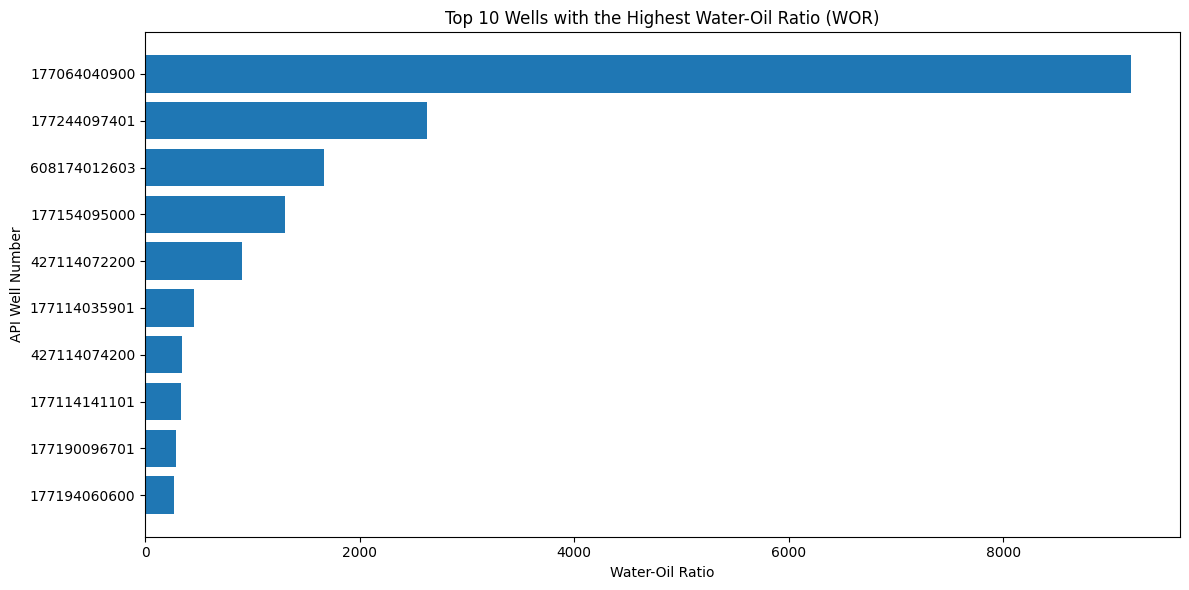

In [63]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_wor_wells.index.astype(str),
    top_10_wor_wells["WOR"]
)

plt.title("Top 10 Wells with the Highest Water-Oil Ratio (WOR)")
plt.xlabel("Water-Oil Ratio")
plt.ylabel("API Well Number")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [64]:
top_oil_wells_with_wor = well_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

top_oil_wells_with_wor[
    ["total_oil", "total_water", "WOR"]
]

,total_oil,total_water,WOR
api_well_number,,,
608174144500,8166097,18845,0.002308
608174101101,5882419,94864,0.016127
608054005400,5644063,9016,0.001597
608174133000,5414667,0,0.000000
608114070600,5350210,5443,0.001017
608124006001,5217804,39994,0.007665
608174132800,4957222,886268,0.178783
608174133900,4925348,2872,0.000583
608174119802,4875798,916738,0.188018


### Water-Oil Ratio Among the Top Oil-Producing Wells

The analysis of the ten highest oil-producing wells revealed generally low Water-Oil Ratios (WOR).

Well 608174144500 recorded the highest oil production of 8,166,097 units, with a WOR of approximately 0.0023.

Among these ten wells, well 608174119802 recorded the highest WOR of approximately 0.1880.

Two wells recorded zero water production during the period analysed.

The results highlight the importance of considering both production volumes and WOR when evaluating well performance. High WOR values should be interpreted alongside absolute oil and water production volumes.

## Key Findings and Observations

### 1. Monthly Production Trends

Oil and gas production showed variations throughout 2024. A notable decline was observed in September, while December recorded higher production volumes, with approximately 58.05 million units of oil and 60.41 million units of gas.

### 2. Operator Performance

SHELL OFFSHORE INC. recorded the highest total oil production of 171.70 million units and gas production of 167.43 million units.

BP EXPLORATION & PRODUCTION INC. recorded the highest water production of approximately 65.34 million units.

### 3. Well Production Performance

The highest oil-producing well was API 608174144500, with a total oil production of 8,166,097 units.

The analysis also showed differences in water production across individual wells, with some high-oil-producing wells recording relatively low water production.

### 4. Relationship Between Production Variables

The correlation analysis revealed:

- Oil and water production: 0.2830 (weak positive correlation).
- Oil and gas production: 0.6469 (moderate positive correlation).

Oil production therefore showed a stronger linear relationship with gas production than with water production.

### 5. Water-Oil Ratio Analysis

The highest calculated WOR was 9,187, recorded by well 177064040900. However, this well produced only one unit of oil.

In comparison, the ten highest oil-producing wells generally recorded much lower WOR values. This demonstrates the importance of considering absolute production volumes alongside WOR when evaluating well performance.

## Conclusion

This exploratory data analysis examined offshore oil and gas production records for 2024 using Python. The analysis involved data inspection, cleaning, quality assessment, aggregation, statistical analysis and visualisation.

The results revealed variations in monthly production, differences in production performance among operators and wells, and relationships between oil, gas and water production.

The correlation analysis showed a moderate positive relationship between oil and gas production and a weaker positive relationship between oil and water production. The Water-Oil Ratio analysis also demonstrated how individual well production profiles can differ significantly.

Overall, this project provided practical insight into how data analytics can support production monitoring, performance comparison and the identification of unusual production patterns in the oil and gas industry.

Further analysis incorporating well characteristics, reservoir properties and longer production histories could provide deeper insight into the factors influencing production performance.